# BDI + character n-grams: *De operibus*


Schema dell'esperimento:

1. carica i testi grezzi da `../data`;
2. normalizza il latino e costruisce campioni di 1000 token;
3. mantiene integralmente fuori dalla calibrazione i due testi di attribuzione incerta `X_operibus.txt` e `X_cilr.txt`;
4. divide i testi di autore noto in circa 70% train e 30% test;
5. sul train esegue 400 verifiche *same author* e 400 *different author*;
6. usa character n-grams 7–9, TF-IDF e BDI con distanza minmax/Ružička;
7. calibra i match strength BDI con regressione logistica, esattamente come nel notebook LambdaG;
8. applica il modello al *De operibus* su 100 campioni di circa 1000 token;
9. confronta il *De operibus* con Ildeberto e poi con tutti gli autori del background corpus.

La regressione logistica viene valutata sul medesimo campione di calibrazione sul quale è stimata, come nel workflow LambdaG attuale. I relativi valori vanno quindi descritti come prestazioni **nel campione di calibrazione**, non come accuratezza su un test indipendente.


## 1. Setup e percorsi

In [3]:
from __future__ import annotations

from pathlib import Path
import sys
import re
import string
import unicodedata
import logging
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import joblib


def find_project_root(start: Path | None = None) -> Path:

    current = (start or Path.cwd()).resolve()

    for folder in [current, *current.parents]:
        if (folder / "data").is_dir() and (folder / "ruzicka").is_dir():
            return folder

    raise FileNotFoundError(
        "Non trovo la cartella di progetto contenente sia 'data' sia 'ruzicka'."
    )


PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data"
RUZICKA_DIR = PROJECT_DIR / "ruzicka"
OUTPUT_DIR = Path.cwd().resolve() / "results_bdi_ngrams"
OUTPUT_DIR.mkdir(exist_ok=True)

# Per poter importare il pacchetto locale ruzicka dalla cartella superiore.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from ruzicka.BDIVerifier import BDIVerifier

logging.getLogger("ruzicka").setLevel(logging.WARNING)

print(f"Project directory: {PROJECT_DIR}")
print(f"Data directory:    {DATA_DIR}")
print(f"Ruzicka package:   {RUZICKA_DIR}")
print(f"Output directory:  {OUTPUT_DIR}")

Project directory: /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Lexical analysis
Data directory:    /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Lexical analysis/data
Ruzicka package:   /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Lexical analysis/ruzicka
Output directory:  /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Lexical analysis/1. De operibus/results_bdi_ngrams


## 2. Parametri dell'esperimento

In [5]:
# -----------------------------
# Corpus e campionamento
# -----------------------------
TARGET_WORK = "operibus"
TARGET_CANDIDATE = "H"

# I due testi problematici devono restare fuori da train e test.
# Li identifichiamo esplicitamente per nome file, così eventuali altri file "X_*"
# non vengono esclusi accidentalmente.
HOLDOUT_FILES = {"X_operibus.txt", "X_cilr.txt"}

TRAIN_PCT = 0.70
SAMPLE_TOKENS = 1000
KNOWN_TOKENS = 2000
REFERENCE_TOKENS = 20000

# Poiché ogni documento BDI ha circa 1000 token:
KNOWN_SAMPLES = max(1, KNOWN_TOKENS // SAMPLE_TOKENS)          # 2
REFERENCE_SAMPLES = max(1, REFERENCE_TOKENS // SAMPLE_TOKENS)  # 20

# -----------------------------
# Character n-grams + BDI
# -----------------------------
NGRAM_RANGE = (3, 5)
MAX_FEATURES = 10_000
N_BOOTSTRAP = 1000
RND_PROP = 0.33

# -----------------------------
# Calibrazione e applicazione
# -----------------------------
N_SAME_AUTHOR = 400
N_DIFFERENT_AUTHOR = 400
N_TARGET_EVALUATIONS = 100

SPLIT_SEED = 42
CALIBRATION_SEED = 42
TARGET_SEED = 123

print("Parameters")
print(f"  sample tokens:       {SAMPLE_TOKENS}")
print(f"  known samples:       {KNOWN_SAMPLES} (~{KNOWN_TOKENS} tokens)")
print(f"  reference samples:   {REFERENCE_SAMPLES} (~{REFERENCE_TOKENS} tokens)")
print(f"  n-grams:             {NGRAM_RANGE}")
print(f"  max features:        {MAX_FEATURES}")
print(f"  bootstrap iterations:{N_BOOTSTRAP}")
print(f"  random feature prop: {RND_PROP}")
print(f"  calibration:         {N_SAME_AUTHOR} same + {N_DIFFERENT_AUTHOR} different")

Parameters
  sample tokens:       1000
  known samples:       2 (~2000 tokens)
  reference samples:   20 (~20000 tokens)
  n-grams:             (7, 9)
  max features:        10000
  bootstrap iterations:1000
  random feature prop: 0.33
  calibration:         400 same + 400 different


## 3. Preprocessing

Si integra nel notebook la normalizzazione che nel vecchio esperimento era stata eseguita in parte sui file prima dell'analisi:

- minuscole;
- `j → i`;
- `v → u`;
- `æ → e` e `ae → e`;
- rimozione della punteggiatura;
- normalizzazione degli spazi.

Il lessico viene mantenuto: qui non si applica il mascheramento POSNoise/LambdaG.


In [7]:
def read_text(path: Path) -> str:
    """Legge UTF-8; usa latin-1 solo come fallback per i vecchi file."""
    try:
        return path.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        return path.read_text(encoding="latin-1")


def remove_unicode_punctuation(text: str) -> str:
    return "".join(
        " " if unicodedata.category(ch).startswith("P") else ch
        for ch in text
    )


def preprocess_text(text: str) -> str:
    text = text.lower()

    # Normalizzazioni grafiche usate nel vecchio esperimento
    text = text.replace("j", "i")
    text = text.replace("v", "u")
    text = text.replace("æ", "e")
    text = text.replace("ae", "e")

    # Rimuove la punteggiatura Unicode e compatta gli spazi
    text = remove_unicode_punctuation(text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def parse_filename(path: Path) -> tuple[str, str]:
    """
    Atteso: <authorcode>_<workcode>.txt
    Il workcode può contenere altri underscore.
    """
    parts = path.stem.split("_", 1)
    if len(parts) != 2:
        raise ValueError(
            f"Nome file non interpretabile: {path.name}. "
            "Atteso '<author>_<work>.txt'."
        )
    return parts[0], parts[1]


txt_files = sorted(
    p for p in DATA_DIR.glob("*.txt")
    if "_sentences" not in p.name
)

if not txt_files:
    raise FileNotFoundError(f"Nessun .txt trovato in {DATA_DIR}")

records = []
texts_by_key = {}

for path in txt_files:
    author, work = parse_filename(path)
    text = preprocess_text(read_text(path))
    n_tokens = len(text.split())

    records.append(
        {
            "file": path.name,
            "author": author,
            "work": work,
            "tokens": n_tokens,
            "holdout": path.name in HOLDOUT_FILES,
        }
    )
    texts_by_key[(author, work)] = text

files_df = pd.DataFrame(records).sort_values(["author", "work"]).reset_index(drop=True)

print(f"Files loaded: {len(files_df)}")
print(f"Known-author files: {(~files_df['holdout']).sum()}")
print(f"Holdout files:      {files_df['holdout'].sum()}")
display(files_df)

Files loaded: 35
Known-author files: 33
Holdout files:      2


,file,author,work,tokens,holdout
0,AE_bhc.txt,AE,bhc,4323,False
1,ASt_troilus.txt,ASt,troilus,37313,False
2,BB_adelae.txt,BB,adelae,8031,False
3,BBi_speculum.txt,BBi,speculum,12438,False
4,BI_reynardus.txt,BI,reynardus,11885,False
5,BM_regum.txt,BM,regum,6628,False
6,BS_mathematicus.txt,BS,mathematicus,5081,False
7,EM_mahumeti.txt,EM,mahumeti,7140,False
8,H_carmina.txt,H,carmina,3617,False
9,H_mysterio.txt,H,mysterio,3786,False


## 4. Individuazione del *De operibus* e degli altri holdout

In [9]:
target_rows = files_df[files_df["work"].str.lower() == TARGET_WORK.lower()]

if len(target_rows) != 1:
    raise ValueError(
        f"Atteso un solo file con work='{TARGET_WORK}', trovati {len(target_rows)}:\n"
        f"{target_rows[['file', 'author', 'work']].to_string(index=False)}"
    )

target_row = target_rows.iloc[0]
TARGET_AUTHOR_CODE = target_row["author"]
target_key = (target_row["author"], target_row["work"])
target_text = texts_by_key[target_key]
target_tokens = target_text.split()

if not bool(target_row["holdout"]):
    raise ValueError(
        f"Il target {target_row['file']} non è incluso in HOLDOUT_FILES={HOLDOUT_FILES}."
    )

print(f"Target: {target_row['file']}")
print(f"Target tokens after preprocessing: {len(target_tokens)}")

print("\nHoldout texts excluded from calibration:")
display(files_df.loc[files_df["holdout"], ["file", "author", "work", "tokens"]])

Target: X_operibus.txt
Target tokens after preprocessing: 1253

Holdout texts excluded from calibration:


,file,author,work,tokens
33,X_cilr.txt,X,cilr,8509
34,X_operibus.txt,X,operibus,1253


## 5. Costruzione dei campioni e split 70/30

Per BDI è utile preservare la sequenza interna del testo. Ogni opera di autore noto viene quindi divisa in blocchi contigui non sovrapposti di 1000 token. I blocchi completi vengono poi assegnati casualmente al train e al test, separatamente per ciascuna opera, in proporzione circa 70/30.

I testi holdout non entrano mai nello split.


In [11]:
def make_full_chunks(
    text: str,
    sample_tokens: int = SAMPLE_TOKENS,
) -> list[str]:
    tokens = text.split()
    n_full = len(tokens) // sample_tokens
    return [
        " ".join(tokens[i * sample_tokens : (i + 1) * sample_tokens])
        for i in range(n_full)
    ]


known_chunk_records = []

for row in files_df.loc[~files_df["holdout"]].itertuples(index=False):
    text = texts_by_key[(row.author, row.work)]
    chunks = make_full_chunks(text)

    if not chunks:
        print(
            f"WARNING: {row.file} ha meno di {SAMPLE_TOKENS} token "
            "e non produce campioni completi."
        )
        continue

    for chunk_number, chunk in enumerate(chunks):
        known_chunk_records.append(
            {
                "author": row.author,
                "work": row.work,
                "file": row.file,
                "chunk_number": chunk_number,
                "tag": f"{row.author}_{row.work}_{chunk_number}",
                "chunk": chunk,
                "tokens": len(chunk.split()),
            }
        )

known_chunks = pd.DataFrame(known_chunk_records)

print(f"Known-author complete chunks: {len(known_chunks)}")
display(
    known_chunks.groupby(["author", "work"])
    .size()
    .rename("n_chunks")
    .reset_index()
)

Known-author complete chunks: 598


,author,work,n_chunks
0,AE,bhc,4
1,ASt,troilus,37
2,BB,adelae,8
3,BBi,speculum,12
4,BI,reynardus,11
5,BM,regum,6
6,BS,mathematicus,5
7,EM,mahumeti,7
8,H,carmina,3
9,H,mysterio,3


In [17]:
def split_chunks_by_work(
    chunks_df: pd.DataFrame,
    train_pct: float = TRAIN_PCT,
    seed: int = SPLIT_SEED,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    rng = np.random.default_rng(seed)

    train_parts = []
    test_parts = []

    for (author, work), group in chunks_df.groupby(["author", "work"], sort=True):
        group = group.copy()
        indices = group.index.to_numpy(copy=True)
        rng.shuffle(indices)

        n = len(indices)

        if n == 1:
            # Non è possibile realizzare un vero 70/30.
            # Manteniamo il campione nel train e segnaliamo il caso.
            train_idx = indices
            test_idx = np.array([], dtype=int)
            print(
                f"WARNING: {author}_{work} ha un solo chunk completo; "
                "assegnato soltanto al train."
            )
        else:
            n_train = int(round(n * train_pct))
            n_train = max(1, min(n - 1, n_train))
            train_idx = indices[:n_train]
            test_idx = indices[n_train:]

        train_parts.append(chunks_df.loc[train_idx])
        if len(test_idx):
            test_parts.append(chunks_df.loc[test_idx])

    train_df = pd.concat(train_parts, ignore_index=True)
    test_df = (
        pd.concat(test_parts, ignore_index=True)
        if test_parts
        else pd.DataFrame(columns=chunks_df.columns)
    )

    return train_df, test_df


train_df, test_df = split_chunks_by_work(known_chunks)

print(f"Train chunks: {len(train_df)}")
print(f"Test chunks:  {len(test_df)}")
print(f"Approx. train tokens: {train_df['tokens'].sum():,}")
print(f"Approx. test tokens:  {test_df['tokens'].sum():,}")

split_summary = (
    pd.concat(
        [
            train_df.assign(split="train"),
            test_df.assign(split="test"),
        ]
    )
    .groupby(["author", "work", "split"])
    .size()
    .unstack(fill_value=0)
)

display(split_summary)

Train chunks: 419
Test chunks:  179
Approx. train tokens: 419,000
Approx. test tokens:  179,000


,split,test,train
author,work,,
AE,bhc,1,3
ASt,troilus,11,26
BB,adelae,2,6
BBi,speculum,4,8
BI,reynardus,3,8
BM,regum,2,4
BS,mathematicus,1,4
EM,mahumeti,2,5
H,carmina,1,2


## 6. Controlli prima della calibrazione

In [20]:
train_author_counts = train_df.groupby("author").size().sort_values()
test_author_counts = test_df.groupby("author").size().sort_values()

print("Train chunks by author:")
display(train_author_counts.rename("n_chunks").to_frame())

print("Test chunks by author:")
display(test_author_counts.rename("n_chunks").to_frame())

# Per un test same-author occorre almeno un altro chunk dello stesso autore
# dopo aver tolto Q.
valid_same_authors = set(train_author_counts[train_author_counts >= 2].index)

invalid_same = sorted(set(train_df["author"]) - valid_same_authors)
if invalid_same:
    print(
        "WARNING: questi autori non possono essere usati come Q nei test "
        "same-author perché hanno meno di 2 chunk nel train:"
    )
    print(invalid_same)

if TARGET_CANDIDATE not in set(test_df["author"]):
    raise ValueError(
        f"Il candidato '{TARGET_CANDIDATE}' non è presente nel test corpus."
    )

Train chunks by author:


,n_chunks
author,
AE,3
U1,3
BM,4
BS,4
H,4
HA,4
SAC,4
U3,4
EM,5


Test chunks by author:


,n_chunks
author,
AE,1
U1,1
BS,1
U3,1
BB,2
BM,2
EM,2
H,2
HA,2


## 7. Funzioni BDI

Per rendere calibrazione e applicazione il più possibile comparabili con LambdaG:

- Q contiene circa 1000 token;
- K contiene fino a 2 campioni del candidato, cioè circa 2000 token;
- la popolazione di riferimento contiene fino a 20 campioni, cioè circa 20.000 token;
- le feature TF-IDF e lo scaler vengono stimati **soltanto sul materiale di confronto del singolo problema**, mai su Q;
- BDI usa 1000 iterazioni bootstrap, `rnd_prop=0.33` e metrica `minmax` (Ružička).


In [43]:
def balanced_reference_sample(
    ref_pool: pd.DataFrame,
    n_samples: int,
    rng: np.random.Generator,
) -> pd.DataFrame:
    """
    Campiona gli impostori favorendo la diversità degli autori:
    un chunk casuale per autore per ciclo, finché si raggiunge n_samples.
    """
    if len(ref_pool) <= n_samples:
        return ref_pool.copy()

    selected_indices = []
    available_by_author = {
        author: group.index.to_list()
        for author, group in ref_pool.groupby("author")
    }

    # Copie mutabili e rimescolate
    for author in available_by_author:
        rng.shuffle(available_by_author[author])

    authors = list(available_by_author)

    while len(selected_indices) < n_samples:
        rng.shuffle(authors)
        added_this_round = 0

        for author in authors:
            if available_by_author[author]:
                selected_indices.append(available_by_author[author].pop())
                added_this_round += 1

                if len(selected_indices) >= n_samples:
                    break

        if added_this_round == 0:
            break

    return ref_pool.loc[selected_indices].copy()


def build_comparison_sample(
    pool_df: pd.DataFrame,
    known_author: str,
    rng: np.random.Generator,
    known_samples: int = KNOWN_SAMPLES,
    reference_samples: int = REFERENCE_SAMPLES,
) -> pd.DataFrame:
    known_pool = pool_df[pool_df["author"] == known_author]
    ref_pool = pool_df[pool_df["author"] != known_author]

    if known_pool.empty:
        raise ValueError(f"Nessun campione disponibile per il candidato {known_author!r}.")
    if ref_pool.empty:
        raise ValueError("Nessun impostore disponibile.")

    n_known = min(known_samples, len(known_pool))
    known_idx = rng.choice(known_pool.index.to_numpy(), size=n_known, replace=False)
    known_part = known_pool.loc[known_idx].copy()

    ref_part = balanced_reference_sample(
        ref_pool,
        min(reference_samples, len(ref_pool)),
        rng,
    )

    return pd.concat([known_part, ref_part], ignore_index=True)


def vectorize_problem(
    comparison_df: pd.DataFrame,
    q_text: str,
):
    """
    Fit di TF-IDF e scaler esclusivamente sul comparison set.
    Q viene soltanto trasformato.
    """
    vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=NGRAM_RANGE,
        use_idf=True,
        norm="l2",
        max_features=MAX_FEATURES,
        lowercase=False,
        decode_error="replace",
    )

    X_comp_sparse = vectorizer.fit_transform(comparison_df["chunk"])
    X_q_sparse = vectorizer.transform([q_text])

    scaler = StandardScaler(with_mean=False)
    X_comp = scaler.fit_transform(X_comp_sparse).toarray()
    X_q = scaler.transform(X_q_sparse).toarray()

    return X_comp, X_q, vectorizer


def run_bdi_problem(
    q_text: str,
    pool_df: pd.DataFrame,
    known_author: str,
    seed: int,
    return_distances: bool = False,
) -> dict:
    rng = np.random.default_rng(seed)

    comparison_df = build_comparison_sample(
        pool_df=pool_df,
        known_author=known_author,
        rng=rng,
    )

    X_comp, X_q, vectorizer = vectorize_problem(comparison_df, q_text)

    label_encoder = LabelEncoder()
    y_comp = label_encoder.fit_transform(comparison_df["author"])

    if known_author not in set(label_encoder.classes_):
        raise ValueError(
            f"Il candidato {known_author!r} non è presente nel comparison set."
        )

    known_label = int(label_encoder.transform([known_author])[0])

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=N_BOOTSTRAP,
        rnd_prop=RND_PROP,
        random_state=np.random.default_rng(seed),
    )
    verifier.fit(X_comp, y_comp)

    match = verifier.predict_proba(
    X_q,
    [known_label],
    nb_imposters=0,
)
    match_strength = float(np.asarray(match).reshape(-1)[0])

    result = {
        "match_strength": match_strength,
        "known_samples_used": int((comparison_df["author"] == known_author).sum()),
        "reference_samples_used": int((comparison_df["author"] != known_author).sum()),
        "n_features": len(vectorizer.get_feature_names_out()),
    }

    if return_distances:
        # Per un solo Q, _dist_arrays contiene normalmente un unico array
        # con le distanze delle iterazioni bootstrap.
        dist = getattr(verifier, "_dist_arrays", None)
        if dist is not None:
            try:
                result["distances"] = np.asarray(dist[0], dtype=float)
            except Exception:
                result["distances"] = np.asarray(dist, dtype=float).reshape(-1)

    return result

## 8. Calibrazione: 400 same-author + 400 different-author

In [46]:
master_rng = np.random.default_rng(CALIBRATION_SEED)

# Q validi per i same-author: dopo l'esclusione del Q deve restare almeno
# un chunk dello stesso autore nel train.
same_q_pool = train_df[train_df["author"].isin(valid_same_authors)].copy()

if same_q_pool.empty:
    raise ValueError("Nessun Q valido per la calibrazione same-author.")

calibration_specs = []

# 400 same-author
same_indices = master_rng.choice(
    same_q_pool.index.to_numpy(),
    size=N_SAME_AUTHOR,
    replace=True,
)

for q_idx in same_indices:
    q_row = train_df.loc[q_idx]
    pool = train_df.drop(index=q_idx).reset_index(drop=True)

    calibration_specs.append(
        {
            "type": "same",
            "q_tag": q_row["tag"],
            "q_author": q_row["author"],
            "known_author": q_row["author"],
            "q_text": q_row["chunk"],
            "pool": pool,
            "seed": int(master_rng.integers(0, 2**32 - 1)),
        }
    )

# 400 different-author
all_q_indices = train_df.index.to_numpy()
different_indices = master_rng.choice(
    all_q_indices,
    size=N_DIFFERENT_AUTHOR,
    replace=True,
)

train_authors = sorted(train_df["author"].unique())

for q_idx in different_indices:
    q_row = train_df.loc[q_idx]
    other_authors = [a for a in train_authors if a != q_row["author"]]

    wrong_author = str(master_rng.choice(other_authors))
    pool = train_df.drop(index=q_idx).reset_index(drop=True)

    calibration_specs.append(
        {
            "type": "different",
            "q_tag": q_row["tag"],
            "q_author": q_row["author"],
            "known_author": wrong_author,
            "q_text": q_row["chunk"],
            "pool": pool,
            "seed": int(master_rng.integers(0, 2**32 - 1)),
        }
    )

print(f"Calibration problems prepared: {len(calibration_specs)}")
print(f"  same author:      {N_SAME_AUTHOR}")
print(f"  different author: {N_DIFFERENT_AUTHOR}")

Calibration problems prepared: 800
  same author:      400
  different author: 400


In [47]:
calibration_results = []

for spec in tqdm(calibration_specs, desc="BDI calibration"):
    try:
        result = run_bdi_problem(
            q_text=spec["q_text"],
            pool_df=spec["pool"],
            known_author=spec["known_author"],
            seed=spec["seed"],
        )

        calibration_results.append(
            {
                "type": spec["type"],
                "q_tag": spec["q_tag"],
                "q_author": spec["q_author"],
                "known_author": spec["known_author"],
                **result,
                "error": None,
            }
        )

    except Exception as exc:
        calibration_results.append(
            {
                "type": spec["type"],
                "q_tag": spec["q_tag"],
                "q_author": spec["q_author"],
                "known_author": spec["known_author"],
                "match_strength": np.nan,
                "known_samples_used": np.nan,
                "reference_samples_used": np.nan,
                "n_features": np.nan,
                "error": repr(exc),
            }
        )

calibration_df = pd.DataFrame(calibration_results)
calibration_df.to_csv(
    OUTPUT_DIR / "bdi_ngram_calibration_results.csv",
    index=False,
)

valid_calibration = calibration_df[calibration_df["error"].isna()].copy()

print(f"Completed: {len(calibration_df)}")
print(f"Valid:     {len(valid_calibration)}")
print(f"Errors:    {calibration_df['error'].notna().sum()}")

if calibration_df["error"].notna().any():
    display(
        calibration_df.loc[
            calibration_df["error"].notna(),
            ["type", "q_tag", "q_author", "known_author", "error"],
        ].head(20)
    )

BDI calibration:   0%|          | 0/800 [00:00<?, ?it/s]

Completed: 800
Valid:     800
Errors:    0


## 9. Esame dei match strength e regressione logistica

In [50]:
display(
    valid_calibration.groupby("type")["match_strength"]
    .agg(["count", "mean", "std", "median", "min", "max"])
)

same_mean = valid_calibration.loc[
    valid_calibration["type"] == "same", "match_strength"
].mean()

different_mean = valid_calibration.loc[
    valid_calibration["type"] == "different", "match_strength"
].mean()

print(f"Mean BDI match strength, same author:      {same_mean:.4f}")
print(f"Mean BDI match strength, different author: {different_mean:.4f}")

,count,mean,std,median,min,max
type,,,,,,
different,400,0.012307,0.062903,0.000,0.0,0.798
same,400,0.821338,0.304511,0.997,0.0,1.000


Mean BDI match strength, same author:      0.8213
Mean BDI match strength, different author: 0.0123


In [54]:
valid_calibration = calibration_df.loc[
    calibration_df["error"].isna()
].copy()

valid_calibration["match_strength"] = pd.to_numeric(
    valid_calibration["match_strength"],
    errors="coerce",
)

valid_calibration = valid_calibration.dropna(
    subset=["match_strength", "type"]
).reset_index(drop=True)

print(f"Rows available for logistic calibration: {len(valid_calibration)}")
print(valid_calibration["type"].value_counts())

y = (valid_calibration["type"] == "same").astype(int).to_numpy()
X_cal = valid_calibration[["match_strength"]].to_numpy(dtype=float)

print(f"X_cal shape: {X_cal.shape}")
print(f"y shape:     {y.shape}")

bdi_calibration_model = LogisticRegression()
bdi_calibration_model.fit(X_cal, y)

Rows available for logistic calibration: 800
type
same         400
different    400
Name: count, dtype: int64
X_cal shape: (800, 1)
y shape:     (800,)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [58]:
y_pred = bdi_calibration_model.predict(X_cal)
y_prob = bdi_calibration_model.predict_proba(X_cal)[:, 1]

valid_calibration["predicted_same"] = y_pred
valid_calibration["calibrated_probability"] = y_prob

coef = float(bdi_calibration_model.coef_[0][0])
intercept = float(bdi_calibration_model.intercept_[0])

threshold_match = -intercept / coef if coef != 0 else np.nan

print(f"Coefficient: {coef:.6f}")
print(f"Intercept: {intercept:.6f}")
print(f"Threshold BDI for P=0.5: {threshold_match:.4f}")

Coefficient: 7.016240
Intercept: -2.137421
Threshold BDI for P=0.5: 0.3046


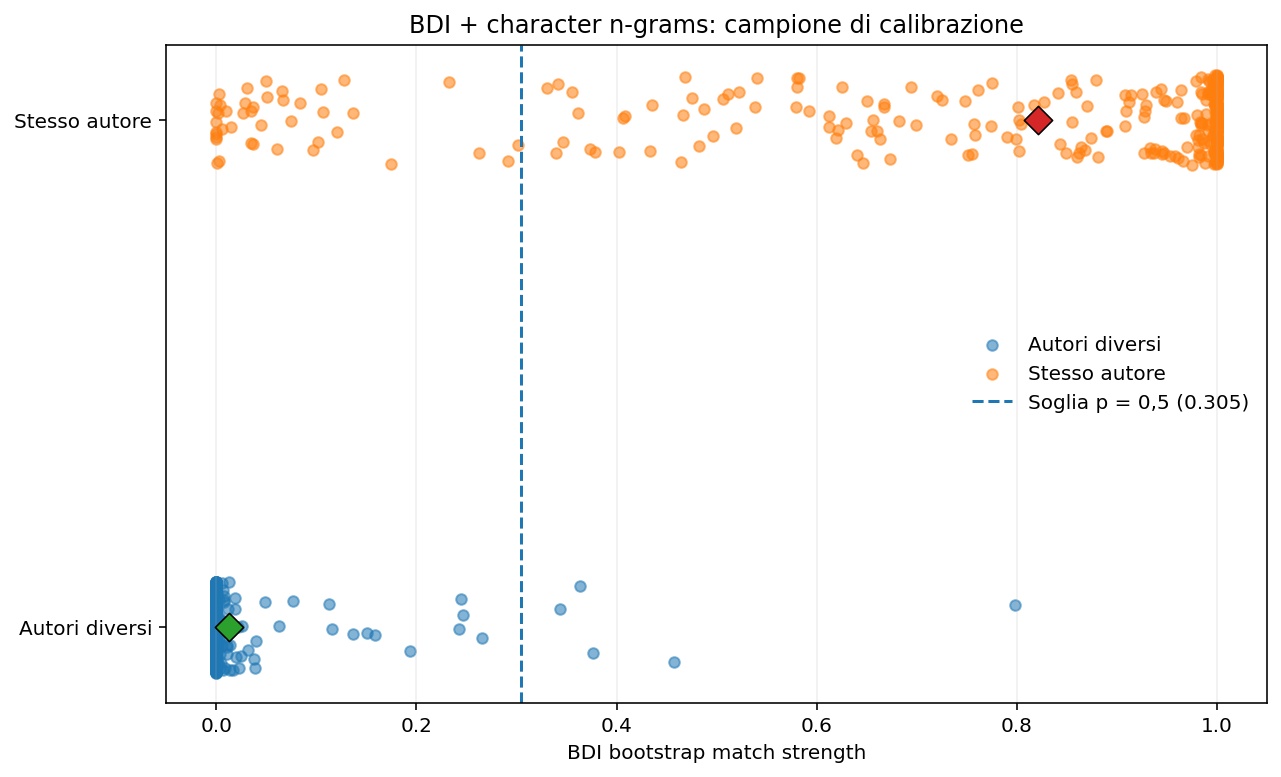

In [60]:
# Visualizzazione analoga a quella del notebook LambdaG
rng_plot = np.random.default_rng(42)

same_scores = valid_calibration.loc[
    valid_calibration["type"] == "same", "match_strength"
].values
different_scores = valid_calibration.loc[
    valid_calibration["type"] == "different", "match_strength"
].values

y_same = 1 + rng_plot.uniform(-0.09, 0.09, size=len(same_scores))
y_different = 0 + rng_plot.uniform(-0.09, 0.09, size=len(different_scores))

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=144)

ax.scatter(different_scores, y_different, s=28, alpha=0.55, label="Autori diversi")
ax.scatter(same_scores, y_same, s=28, alpha=0.55, label="Stesso autore")

if np.isfinite(threshold_match):
    ax.axvline(
        threshold_match,
        linestyle="--",
        linewidth=1.5,
        label=f"Soglia p = 0,5 ({threshold_match:.3f})",
    )

ax.scatter(
    different_scores.mean(),
    0,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)
ax.scatter(
    same_scores.mean(),
    1,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Autori diversi", "Stesso autore"])
ax.set_xlabel("BDI bootstrap match strength")
ax.set_ylabel("")
ax.set_title("BDI + character n-grams: campione di calibrazione")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "bdi_ngram_calibration_match_strength.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    OUTPUT_DIR / "bdi_ngram_calibration_match_strength.pdf",
    bbox_inches="tight",
)
plt.show()

## 10. Campionamento del *De operibus*

Per conservare l'informazione locale degli n-grammi, i 100 Q del *De operibus* sono finestre contigue casuali di 1000 token. Le finestre possono sovrapporsi, come avviene in un campionamento ripetuto.


In [63]:
def random_contiguous_windows(
    tokens: list[str],
    sample_tokens: int,
    n_samples: int,
    seed: int,
) -> pd.DataFrame:
    if len(tokens) < sample_tokens:
        raise ValueError(
            f"Il testo ha {len(tokens)} token, meno dei {sample_tokens} richiesti."
        )

    rng = np.random.default_rng(seed)
    max_start = len(tokens) - sample_tokens

    starts = rng.integers(
        0,
        max_start + 1,
        size=n_samples,
    )

    records = []
    for i, start in enumerate(starts):
        end = int(start) + sample_tokens
        records.append(
            {
                "sample_id": i,
                "start_token": int(start),
                "end_token": int(end),
                "chunk": " ".join(tokens[int(start):end]),
                "tokens": sample_tokens,
            }
        )

    return pd.DataFrame(records)


operibus_samples = random_contiguous_windows(
    target_tokens,
    sample_tokens=SAMPLE_TOKENS,
    n_samples=N_TARGET_EVALUATIONS,
    seed=TARGET_SEED,
)

print(f"De operibus samples: {len(operibus_samples)}")
display(operibus_samples.head())

De operibus samples: 100


,sample_id,start_token,end_token,chunk,tokens
0,0,3,1003,coelumque solumque fecit principium filius eiu...,1000
1,1,173,1173,prefertur spiritibusque subest nam lex diuinis...,1000
2,2,150,1150,utrasque hoc firmamentum constituens medium ha...,1000
3,3,13,1013,coelum qui coelica mente requirunt et terram n...,1000
4,4,230,1230,hinc herbam uiridem fructumque ferentia ligna ...,1000


## 11. *De operibus* vs Ildeberto

In [66]:
def evaluate_target_against_author(
    target_samples_df: pd.DataFrame,
    comparison_pool: pd.DataFrame,
    known_author: str,
    seed: int,
    keep_distances: bool = False,
) -> pd.DataFrame:
    master_rng = np.random.default_rng(seed)
    rows = []

    for row in tqdm(
        target_samples_df.itertuples(index=False),
        total=len(target_samples_df),
        desc=f"De operibus vs {known_author}",
    ):
        problem_seed = int(master_rng.integers(0, 2**32 - 1))

        try:
            result = run_bdi_problem(
                q_text=row.chunk,
                pool_df=comparison_pool,
                known_author=known_author,
                seed=problem_seed,
                return_distances=keep_distances,
            )

            out = {
                "sample_id": row.sample_id,
                "start_token": row.start_token,
                "end_token": row.end_token,
                "author": known_author,
                "match_strength": result["match_strength"],
                "known_samples_used": result["known_samples_used"],
                "reference_samples_used": result["reference_samples_used"],
                "n_features": result["n_features"],
                "error": None,
            }

            if keep_distances and "distances" in result:
                out["distances"] = result["distances"]

            rows.append(out)

        except Exception as exc:
            rows.append(
                {
                    "sample_id": row.sample_id,
                    "start_token": row.start_token,
                    "end_token": row.end_token,
                    "author": known_author,
                    "match_strength": np.nan,
                    "known_samples_used": np.nan,
                    "reference_samples_used": np.nan,
                    "n_features": np.nan,
                    "error": repr(exc),
                }
            )

    return pd.DataFrame(rows)


operibus_h = evaluate_target_against_author(
    target_samples_df=operibus_samples,
    comparison_pool=test_df,
    known_author=TARGET_CANDIDATE,
    seed=TARGET_SEED + 1000,
    keep_distances=True,
)

valid_h = operibus_h[operibus_h["error"].isna()].copy()

valid_h["calibrated_probability"] = bdi_calibration_model.predict_proba(
    valid_h["match_strength"].values.reshape(-1, 1)
)[:, 1]

print("=== De operibus vs Hildebert ===")
print(valid_h[["match_strength", "calibrated_probability"]].describe())

print(f"\nMean match strength:          {valid_h['match_strength'].mean():.4f}")
print(f"Median match strength:        {valid_h['match_strength'].median():.4f}")
print(f"Mean calibrated probability:  {valid_h['calibrated_probability'].mean():.4f}")
print(f"Median calibrated probability:{valid_h['calibrated_probability'].median():.4f}")

# Salva senza la colonna object contenente gli array bootstrap
valid_h.drop(columns=["distances"], errors="ignore").to_csv(
    OUTPUT_DIR / "de_operibus_vs_hildebert_bdi_ngrams.csv",
    index=False,
)

De operibus vs H:   0%|          | 0/100 [00:00<?, ?it/s]

=== De operibus vs Hildebert ===
       match_strength  calibrated_probability
count      100.000000              100.000000
mean         0.169580                0.307033
std          0.190716                0.252142
min          0.000000                0.105513
25%          0.030500                0.127482
50%          0.086500                0.177919
75%          0.258500                0.419880
max          0.803000                0.970591

Mean match strength:          0.1696
Median match strength:        0.0865
Mean calibrated probability:  0.3070
Median calibrated probability:0.1779


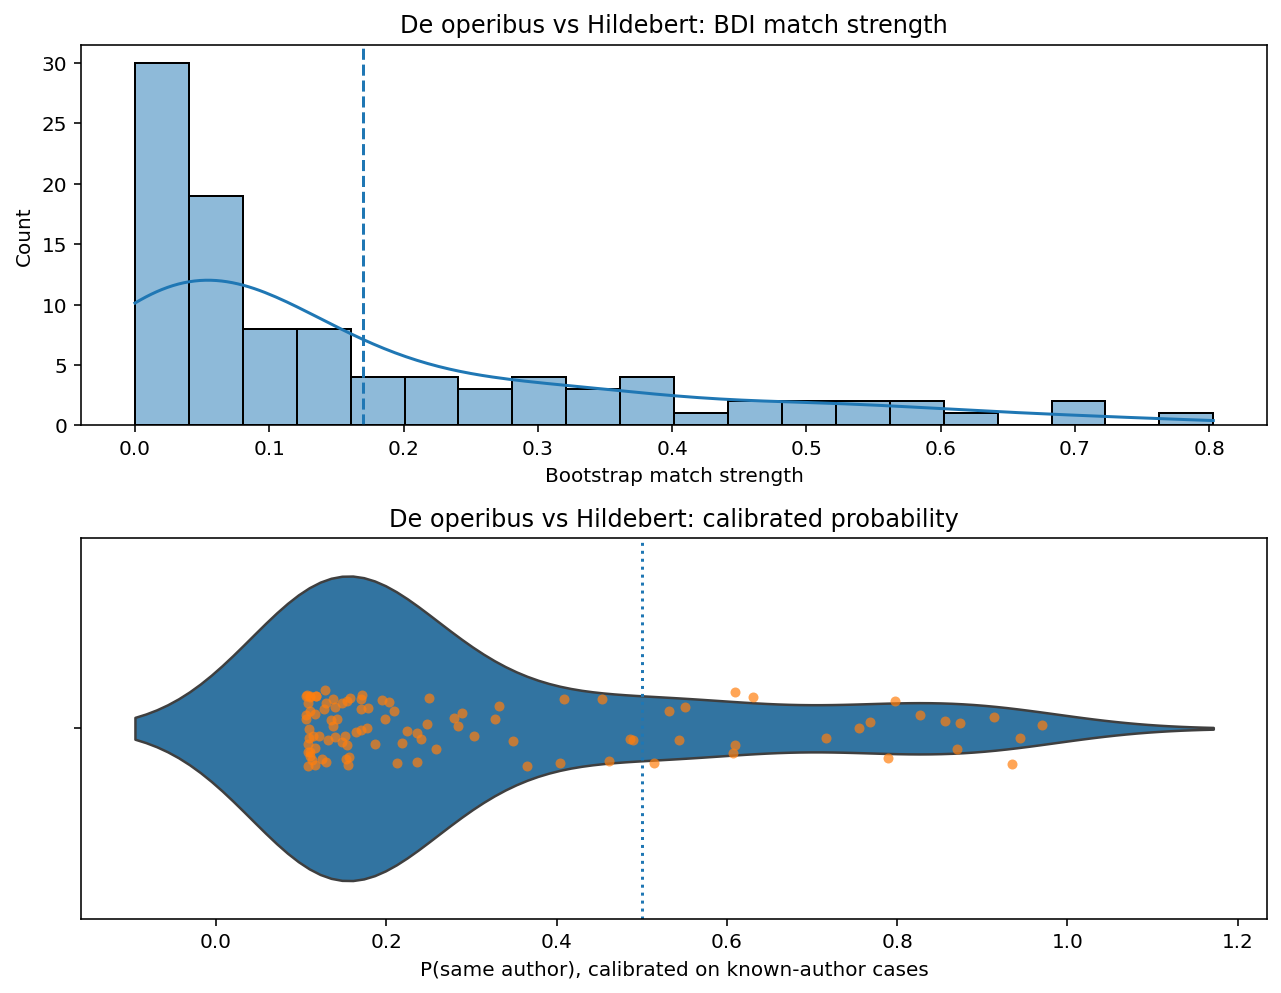

In [67]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), dpi=144)

sns.histplot(
    data=valid_h,
    x="match_strength",
    bins=20,
    kde=True,
    ax=axes[0],
)
axes[0].axvline(valid_h["match_strength"].mean(), linestyle="--")
axes[0].set_title("De operibus vs Hildebert: BDI match strength")
axes[0].set_xlabel("Bootstrap match strength")

sns.violinplot(
    data=valid_h,
    x="calibrated_probability",
    ax=axes[1],
    inner=None,
)
sns.stripplot(
    data=valid_h,
    x="calibrated_probability",
    ax=axes[1],
    jitter=True,
    alpha=0.7,
)
axes[1].axvline(0.5, linestyle=":")
axes[1].set_title("De operibus vs Hildebert: calibrated probability")
axes[1].set_xlabel("P(same author), calibrated on known-author cases")

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "de_operibus_vs_hildebert_bdi_ngrams.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 12. Distribuzione delle distanze bootstrap per Ildeberto

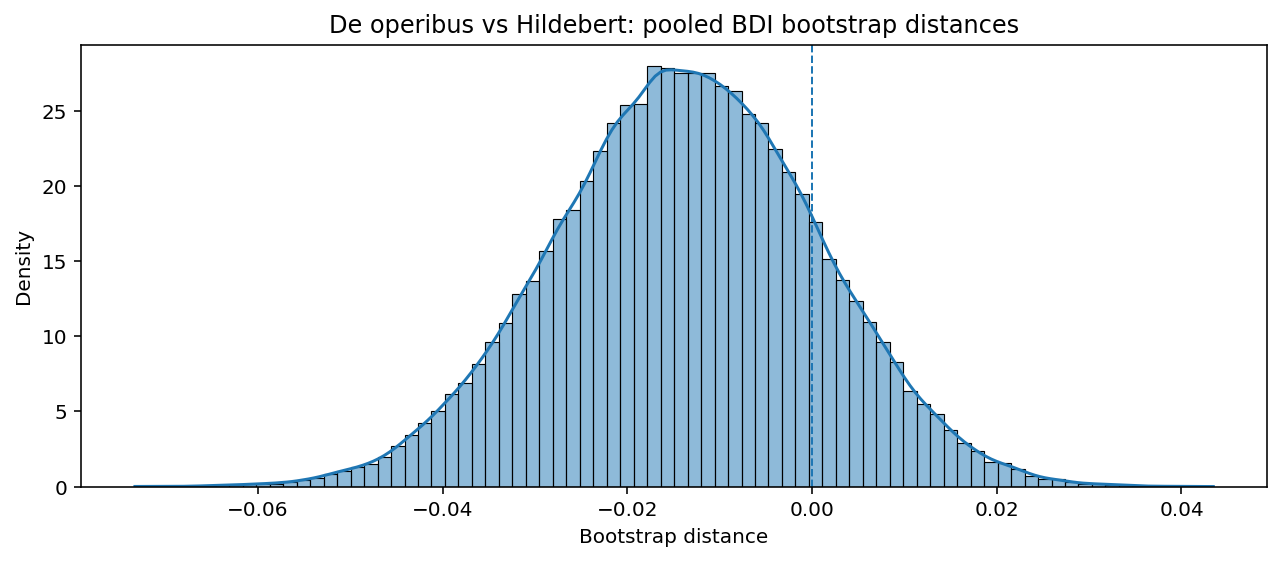

In [69]:
distance_rows = []

for row in valid_h.itertuples(index=False):
    if hasattr(row, "distances") and row.distances is not None:
        for iteration, distance in enumerate(np.asarray(row.distances).reshape(-1)):
            distance_rows.append(
                {
                    "sample_id": row.sample_id,
                    "bootstrap_iteration": iteration,
                    "distance": float(distance),
                }
            )

if distance_rows:
    distances_h = pd.DataFrame(distance_rows)
    distances_h.to_csv(
        OUTPUT_DIR / "de_operibus_vs_hildebert_bootstrap_distances.csv",
        index=False,
    )

    fig, ax = plt.subplots(figsize=(9, 4), dpi=144)
    sns.histplot(
        data=distances_h,
        x="distance",
        bins=80,
        kde=True,
        stat="density",
        ax=ax,
    )
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title("De operibus vs Hildebert: pooled BDI bootstrap distances")
    ax.set_xlabel("Bootstrap distance")
    ax.set_ylabel("Density")
    plt.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "de_operibus_vs_hildebert_bootstrap_distances.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
else:
    print("Nessuna distanza bootstrap disponibile in _dist_arrays.")

## 13. *De operibus* vs tutti gli autori del background corpus

In [71]:
candidate_authors = sorted(test_df["author"].unique())

all_author_frames = []

for author_index, author in enumerate(candidate_authors):
    print(f"\n[{author_index + 1}/{len(candidate_authors)}] Candidate: {author}")

    author_df = evaluate_target_against_author(
        target_samples_df=operibus_samples,
        comparison_pool=test_df,
        known_author=author,
        seed=TARGET_SEED + 10_000 + author_index,
        keep_distances=False,
    )

    valid_author = author_df[author_df["error"].isna()].copy()

    if len(valid_author):
        valid_author["calibrated_probability"] = (
            bdi_calibration_model.predict_proba(
                valid_author["match_strength"].values.reshape(-1, 1)
            )[:, 1]
        )

    all_author_frames.append(valid_author)

operibus_all = pd.concat(all_author_frames, ignore_index=True)

operibus_all.to_csv(
    OUTPUT_DIR / "de_operibus_all_authors_bdi_ngrams.csv",
    index=False,
)

summary = (
    operibus_all.groupby("author")
    .agg(
        match_mean=("match_strength", "mean"),
        match_std=("match_strength", "std"),
        probability_mean=("calibrated_probability", "mean"),
        probability_std=("calibrated_probability", "std"),
        probability_median=("calibrated_probability", "median"),
        probability_q25=("calibrated_probability", lambda x: x.quantile(0.25)),
        probability_q75=("calibrated_probability", lambda x: x.quantile(0.75)),
        n=("calibrated_probability", "count"),
    )
    .sort_values("probability_mean", ascending=False)
)

summary.to_csv(
    OUTPUT_DIR / "de_operibus_all_authors_bdi_ngrams_summary.csv"
)

display(summary)


[1/27] Candidate: AE


De operibus vs AE:   0%|          | 0/100 [00:00<?, ?it/s]


[2/27] Candidate: ASt


De operibus vs ASt:   0%|          | 0/100 [00:00<?, ?it/s]


[3/27] Candidate: BB


De operibus vs BB:   0%|          | 0/100 [00:00<?, ?it/s]


[4/27] Candidate: BBi


De operibus vs BBi:   0%|          | 0/100 [00:00<?, ?it/s]


[5/27] Candidate: BI


De operibus vs BI:   0%|          | 0/100 [00:00<?, ?it/s]


[6/27] Candidate: BM


De operibus vs BM:   0%|          | 0/100 [00:00<?, ?it/s]


[7/27] Candidate: BS


De operibus vs BS:   0%|          | 0/100 [00:00<?, ?it/s]


[8/27] Candidate: EM


De operibus vs EM:   0%|          | 0/100 [00:00<?, ?it/s]


[9/27] Candidate: H


De operibus vs H:   0%|          | 0/100 [00:00<?, ?it/s]


[10/27] Candidate: HA


De operibus vs HA:   0%|          | 0/100 [00:00<?, ?it/s]


[11/27] Candidate: HM


De operibus vs HM:   0%|          | 0/100 [00:00<?, ?it/s]


[12/27] Candidate: HW


De operibus vs HW:   0%|          | 0/100 [00:00<?, ?it/s]


[13/27] Candidate: IS


De operibus vs IS:   0%|          | 0/100 [00:00<?, ?it/s]


[14/27] Candidate: M


De operibus vs M:   0%|          | 0/100 [00:00<?, ?it/s]


[15/27] Candidate: NLC


De operibus vs NLC:   0%|          | 0/100 [00:00<?, ?it/s]


[16/27] Candidate: PDE


De operibus vs PDE:   0%|          | 0/100 [00:00<?, ?it/s]


[17/27] Candidate: PR


De operibus vs PR:   0%|          | 0/100 [00:00<?, ?it/s]


[18/27] Candidate: QS


De operibus vs QS:   0%|          | 0/100 [00:00<?, ?it/s]


[19/27] Candidate: RDV


De operibus vs RDV:   0%|          | 0/100 [00:00<?, ?it/s]


[20/27] Candidate: RL


De operibus vs RL:   0%|          | 0/100 [00:00<?, ?it/s]


[21/27] Candidate: RT


De operibus vs RT:   0%|          | 0/100 [00:00<?, ?it/s]


[22/27] Candidate: SAC


De operibus vs SAC:   0%|          | 0/100 [00:00<?, ?it/s]


[23/27] Candidate: SR


De operibus vs SR:   0%|          | 0/100 [00:00<?, ?it/s]


[24/27] Candidate: U1


De operibus vs U1:   0%|          | 0/100 [00:00<?, ?it/s]


[25/27] Candidate: U2


De operibus vs U2:   0%|          | 0/100 [00:00<?, ?it/s]


[26/27] Candidate: U3


De operibus vs U3:   0%|          | 0/100 [00:00<?, ?it/s]


[27/27] Candidate: U4


De operibus vs U4:   0%|          | 0/100 [00:00<?, ?it/s]

,match_mean,match_std,probability_mean,probability_std,probability_median,probability_q25,probability_q75,n
author,,,,,,,,
AE,0.56325,0.238179,0.773165,0.247343,0.872261,0.701983,0.964011,100
PR,0.16708,0.248803,0.302985,0.298558,0.127485,0.106677,0.428785,100
H,0.16117,0.190291,0.297067,0.246082,0.167397,0.117311,0.412956,100
HW,0.15637,0.239243,0.287764,0.284084,0.130239,0.106011,0.362373,100
BM,0.10560,0.120965,0.217804,0.149663,0.150526,0.121741,0.256275,100
IS,0.03953,0.086671,0.146388,0.109247,0.107516,0.105513,0.135285,100
EM,0.03764,0.072670,0.144026,0.090966,0.111275,0.106844,0.130436,100
BB,0.03775,0.079140,0.143451,0.102569,0.111622,0.106177,0.133449,100
RL,0.02643,0.071695,0.132649,0.089810,0.107516,0.105513,0.115328,100


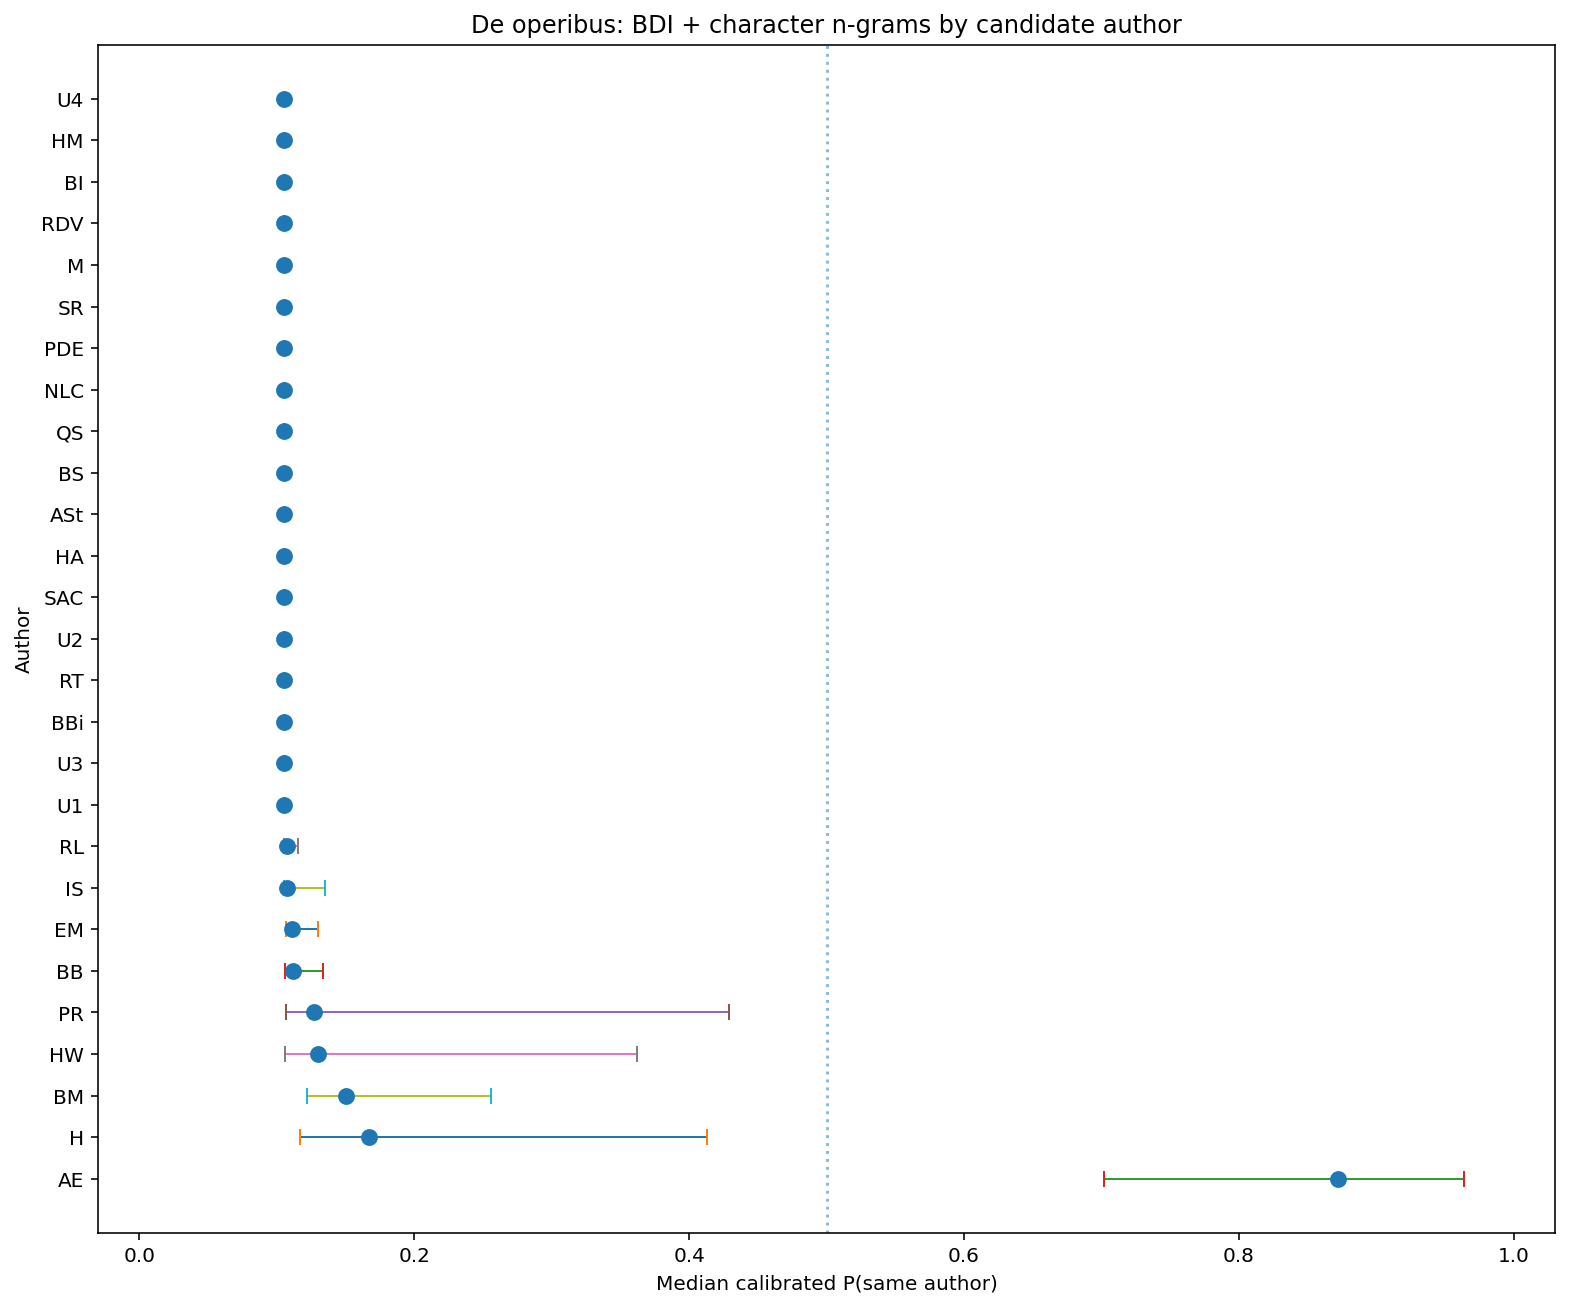

In [72]:
plot_stats = summary.sort_values("probability_median", ascending=True)
authors_ordered = plot_stats.index.tolist()

fig_height = max(8, 0.34 * len(authors_ordered))
fig, ax = plt.subplots(figsize=(11, fig_height), dpi=144)

for i, author in enumerate(authors_ordered):
    row = plot_stats.loc[author]
    ax.plot(
        [row["probability_q25"], row["probability_q75"]],
        [i, i],
        linewidth=1,
        zorder=2,
    )
    ax.plot(
        [row["probability_q25"], row["probability_q75"]],
        [i, i],
        "|",
        markersize=8,
        zorder=3,
    )

ax.scatter(
    plot_stats["probability_median"].values,
    range(len(authors_ordered)),
    s=55,
    zorder=5,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered)
ax.invert_yaxis()

ax.axvline(0.5, linestyle=":", alpha=0.5)

ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("Median calibrated P(same author)")
ax.set_ylabel("Author")
ax.set_title("De operibus: BDI + character n-grams by candidate author")

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "de_operibus_all_authors_bdi_ngrams.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 14. Output prodotti

La cartella `results_bdi_ngrams` contiene:

- `bdi_ngram_calibration_results.csv`
- `bdi_ngram_calibration_results_with_probabilities.csv`
- `bdi_ngram_logistic_regression_model.pkl`
- grafici della calibrazione
- `de_operibus_vs_hildebert_bdi_ngrams.csv`
- distribuzioni bootstrap del confronto con Ildeberto
- `de_operibus_all_authors_bdi_ngrams.csv`
- `de_operibus_all_authors_bdi_ngrams_summary.csv`
- grafico riassuntivo per tutti i candidati

Per l'interpretazione, il valore restituito direttamente da BDI rimane un **bootstrap match strength**, non una probabilità. La colonna `calibrated_probability` è invece la trasformazione empirica ottenuta dalla regressione logistica sui confronti di autore noto.
